# 1. Business Problem

Businesses have many customers, but all customers are not equally valuable.

### Some customers:

purchase recently,
purchase frequently,
spend more money.

### Other customers:

purchase less,
may become inactive,
need re-engagement.

### Goal:

#### Segment customers into meaningful groups such as:

high value customers,
regular customers,
inactive customers,
low spend customers.

### Business value:
targeted marketing,
better retention strategy,
improved customer lifetime value.

# 2.Notebook Code

#### 1.Import libraries

In [1]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

import warnings 
warnings.filterwarnings('ignore')


In [2]:
df = pd.read_csv("online_retail.csv", encoding="latin1")

In [3]:
df    

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [4]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


#### Check shape and info

In [5]:
print("Shape of dataset:", df.shape)

Shape of dataset: (541909, 8)


In [6]:
print(df.columns.tolist())

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


#### Basic statistics

In [8]:
df.describe(include='all')

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900,4070,4223,NaN,23260,NaN,NaN,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,2011-10-31 14:41:00,NaN,NaN,United Kingdom
freq,1114,2313,2369,NaN,1114,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,NaN,4.611114,15287.690570,NaN
std,NaN,NaN,NaN,218.081158,NaN,96.759853,1713.600303,NaN
min,NaN,NaN,NaN,-80995.000000,NaN,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,NaN,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,NaN,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,NaN,4.130000,16791.000000,NaN


#### Missing values check

In [9]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


#### Duplicate rows check

In [10]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 5268


#### Remove duplicates

In [11]:
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (536641, 8)


# 3.Data Cleaning

#### Remove rows with missing CustomerID

In [12]:
df = df.dropna(subset=["CustomerID"])
print("Shape after dropping missing CustomerID:", df.shape)

Shape after dropping missing CustomerID: (401604, 8)


#### Convert InvoiceDate

In [13]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

#### Remove invalid values

In [14]:
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
print("Shape after removing invalid Quantity/Price:", df.shape)

Shape after removing invalid Quantity/Price: (392692, 8)


#### Create TotalAmount

In [15]:
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


# Outlier Check

#### Check distributions

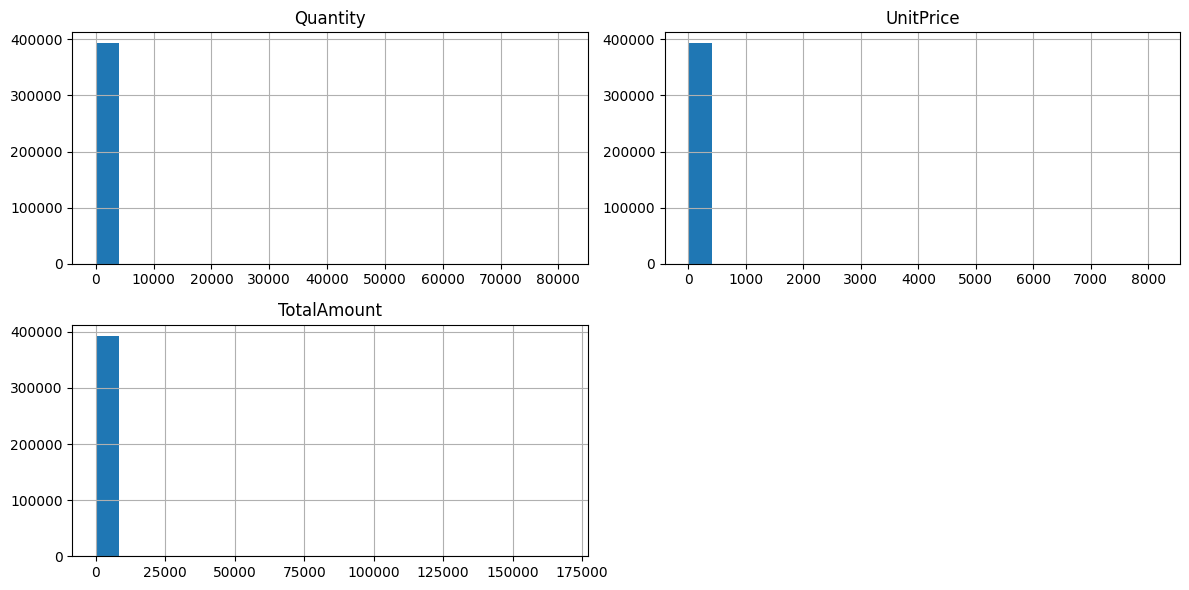

In [16]:
num_cols = ["Quantity", "UnitPrice", "TotalAmount"]

df[num_cols].hist(figsize=(12, 6), bins=20)
plt.tight_layout()
plt.show()

#### Boxplots for outliers

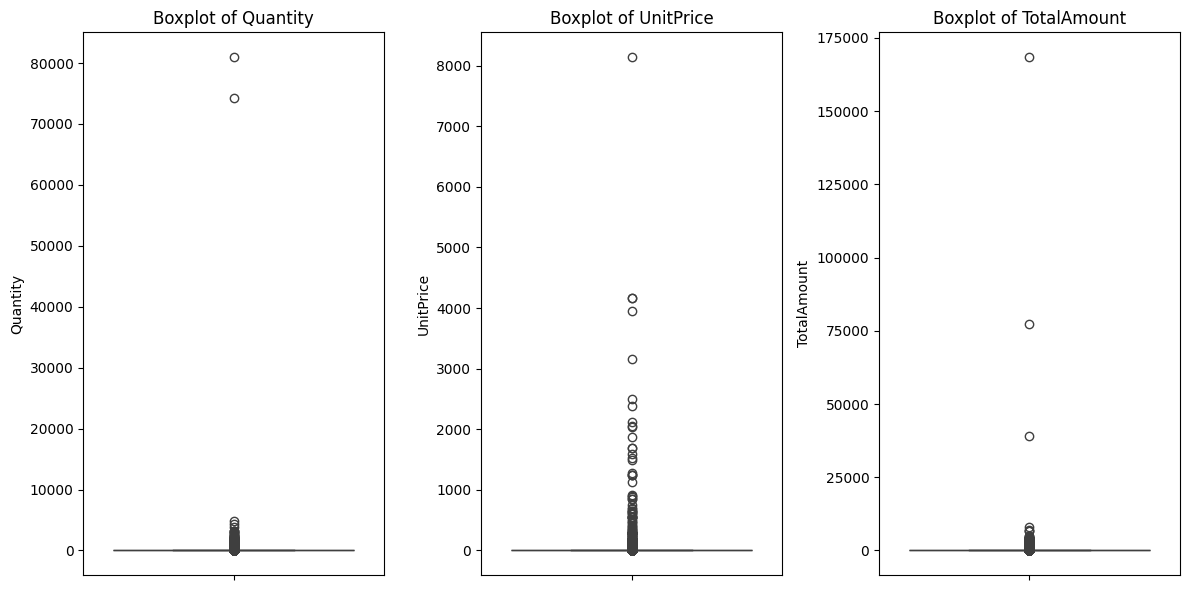

In [17]:
plt.figure(figsize=(12,6))

for i, col in enumerate(num_cols, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=df[col])
    plt.title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

#### Outlier capping function

In [18]:
def cap_outliers_iqr(dataframe, column):
    Q1 = dataframe[column].quantile(0.25)
    Q3 = dataframe[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    dataframe[column] = np.where(dataframe[column] < lower, lower, dataframe[column])
    dataframe[column] = np.where(dataframe[column] > upper, upper, dataframe[column])

    return dataframe

#### Apply capping

In [19]:
for col in num_cols:
    df = cap_outliers_iqr(df, col)

df[num_cols].describe()

,Quantity,UnitPrice,TotalAmount
count,392692.000000,392692.000000,392692.000000
mean,8.393176,2.602209,14.483715
std,8.109098,2.106173,11.916140
min,1.000000,0.001000,0.001000
25%,2.000000,1.250000,4.950000
50%,6.000000,1.950000,12.450000
75%,12.000000,3.750000,19.800000
max,27.000000,7.500000,42.075000


# 5. Store Data in SQL

#### Create SQL connection

In [20]:
conn = sqlite3.connect("customer_segmentation.db")

#### Store dataframe into SQL

In [21]:
df.to_sql("retail_data", conn, if_exists="replace", index=False)
print("Data stored in SQL successfully")

Data stored in SQL successfully


# 6. SQL Analysis

#### Total customers

In [22]:
query1 = """
SELECT COUNT(DISTINCT CustomerID) AS total_customers
FROM retail_data;
"""

pd.read_sql(query1, conn)

,total_customers
0,4338


#### Total revenue

In [23]:
query2 = """
SELECT ROUND(SUM(TotalAmount), 2) AS total_revenue
FROM retail_data;
"""

pd.read_sql(query2, conn)

,total_revenue
0,5687638.83


#### Top 10 customers by spending

In [24]:
query3 = """
SELECT CustomerID, ROUND(SUM(TotalAmount), 2) AS total_spent
FROM retail_data
GROUP BY CustomerID
ORDER BY total_spent DESC
LIMIT 10;
"""

pd.read_sql(query3, conn)

,CustomerID,total_spent
0,14911.0,113880.08
1,14646.0,76676.24
2,14096.0,49294.36
3,13089.0,43201.59
4,14298.0,41044.99
5,17841.0,37850.85
6,14156.0,36748.23
7,17511.0,33868.29
8,15311.0,30577.45
9,12748.0,27343.56


#### Top 10 products by revenue

In [25]:
query4 = """
SELECT Description, ROUND(SUM(TotalAmount), 2) AS revenue
FROM retail_data
GROUP BY Description
ORDER BY revenue DESC
LIMIT 10;
"""

pd.read_sql(query4, conn)

,Description,revenue
0,REGENCY CAKESTAND 3 TIER,50701.43
1,WHITE HANGING HEART T-LIGHT HOLDER,44941.24
2,POSTAGE,37893.14
3,JUMBO BAG RED RETROSPOT,37021.72
4,PARTY BUNTING,35107.36
5,ASSORTED COLOUR BIRD ORNAMENT,33409.63
6,SPOTTY BUNTING,22284.90
7,JAM MAKING SET WITH JARS,21950.25
8,PAPER CHAIN KIT 50'S CHRISTMAS,21813.73
9,LUNCH BAG RED RETROSPOT,20738.90


#### Monthly revenue trend

In [26]:
query5 = """
SELECT 
    strftime('%Y-%m', InvoiceDate) AS month,
    ROUND(SUM(TotalAmount), 2) AS monthly_revenue
FROM retail_data
GROUP BY month
ORDER BY month;
"""

monthly_revenue = pd.read_sql(query5, conn)
monthly_revenue

,month,monthly_revenue
0,2010-12,374853.55
1,2011-01,316001.93
2,2011-02,299159.99
3,2011-03,393501.53
4,2011-04,325333.48
5,2011-05,445342.04
6,2011-06,400798.58
7,2011-07,387977.46
8,2011-08,413721.59
9,2011-09,612395.96


#### Plot monthly revenue

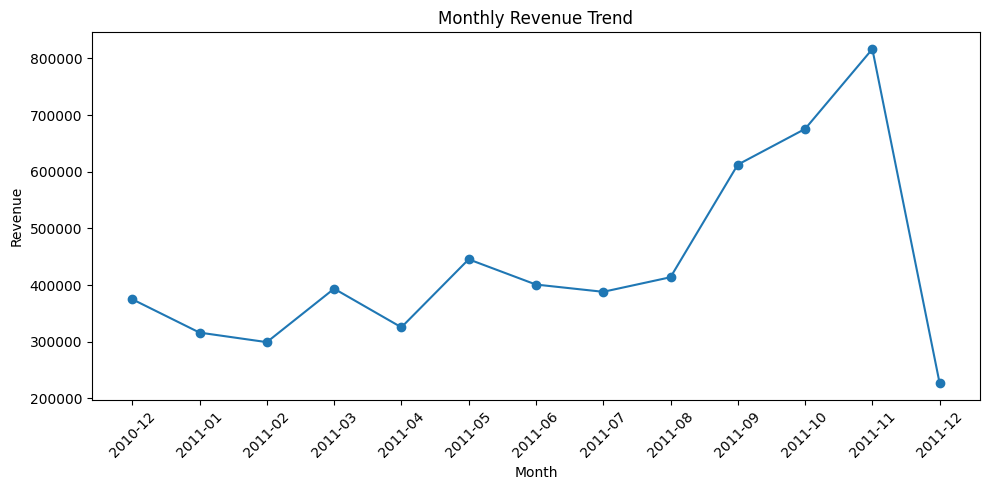

In [27]:
plt.figure(figsize=(10,5))
plt.plot(monthly_revenue["month"], monthly_revenue["monthly_revenue"], marker="o")
plt.xticks(rotation=45)
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

#### Orders by country

In [28]:
query6 = """
SELECT Country, COUNT(DISTINCT InvoiceNo) AS total_orders
FROM retail_data
GROUP BY Country
ORDER BY total_orders DESC;
"""

pd.read_sql(query6, conn).head(10)

,Country,total_orders
0,United Kingdom,16646
1,Germany,457
2,France,389
3,EIRE,260
4,Belgium,98
5,Netherlands,94
6,Spain,90
7,Portugal,57
8,Australia,57
9,Switzerland,51


# 7. RFM Feature Engineering

#### Snapshot date

In [29]:
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)
print("Snapshot Date:", snapshot_date)

Snapshot Date: 2011-12-10 12:50:00


#### Create RFM table

In [30]:
rfm = df.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (snapshot_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalAmount": "sum"
}).reset_index()

rfm.columns = ["CustomerID", "Recency", "Frequency", "Monetary"]

rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,42.075
1,12347.0,2,7,3763.670
2,12348.0,75,4,1106.540
3,12349.0,19,1,1439.875
4,12350.0,310,1,334.400


#### RFM summary

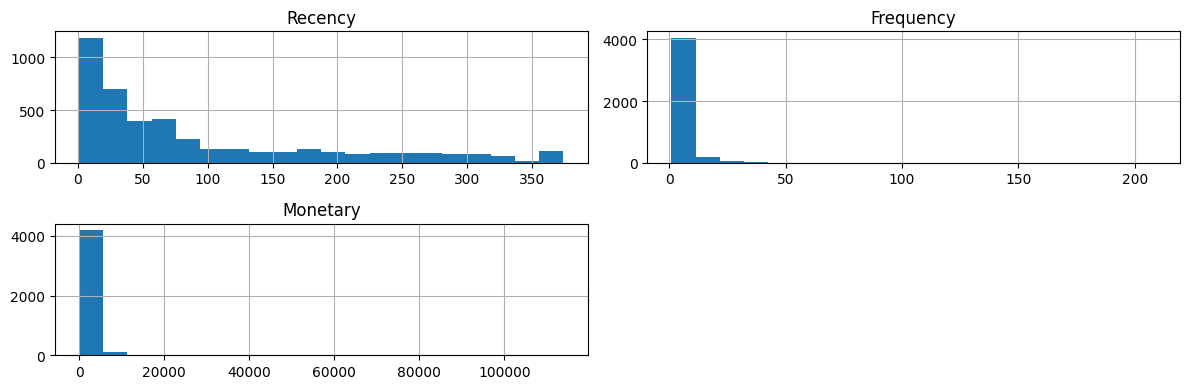

In [31]:
rfm[["Recency", "Frequency", "Monetary"]].hist(figsize=(12,4), bins=20)
plt.tight_layout()
plt.show()

#### Boxplots for RFM

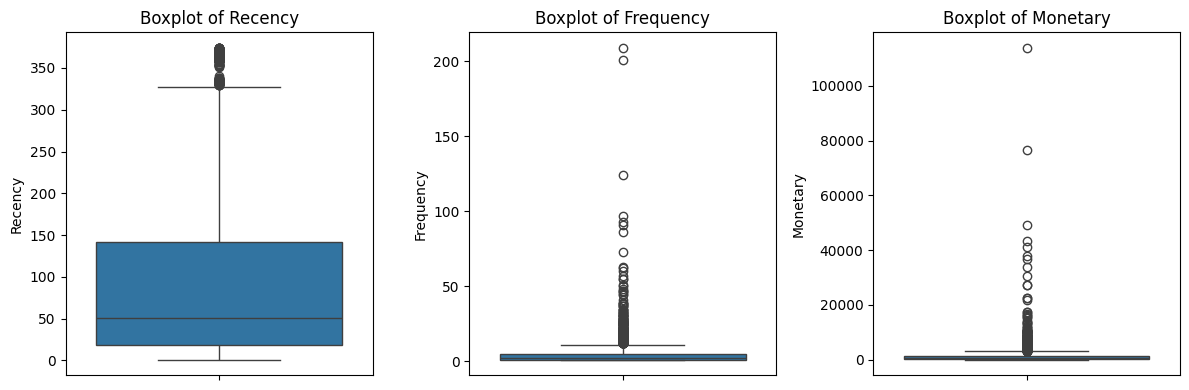

In [32]:
plt.figure(figsize=(12,4))

for i, col in enumerate(["Recency", "Frequency", "Monetary"], 1):
    plt.subplot(1,3,i)
    sns.boxplot(y=rfm[col])
    plt.title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

#### Log transform RFM

In [33]:
rfm["Recency_log"] = np.log1p(rfm["Recency"])
rfm["Frequency_log"] = np.log1p(rfm["Frequency"])
rfm["Monetary_log"] = np.log1p(rfm["Monetary"])

# 8. Scaling

#### Select final clustering features

In [34]:
features = rfm[["Recency_log", "Frequency_log", "Monetary_log"]]
features.head()

,Recency_log,Frequency_log,Monetary_log
0,5.789960,0.693147,3.762943
1,1.098612,2.079442,8.233415
2,4.330733,1.609438,7.009897
3,2.995732,0.693147,7.273006
4,5.739793,0.693147,5.815324


#### Scale features

In [35]:
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

scaled_features[:5]

array([[ 1.46199281, -0.95521426, -2.1706928 ],
       [-2.03873442,  1.07442519,  1.51395192],
       [ 0.37310424,  0.38630445,  0.50550547],
       [-0.62308592, -0.95521426,  0.72236487],
       [ 1.42455753, -0.95521426, -0.47908308]])

# 9. Elbow Method

#### Elbow method

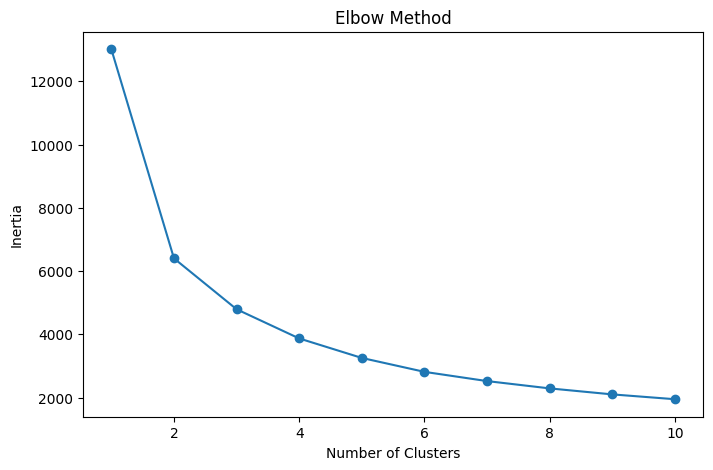

In [36]:
inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(scaled_features)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(range(1, 11), inertia, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.show()

#### Silhouette score

In [37]:
for k in range(2, 7):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(scaled_features)
    score = silhouette_score(scaled_features, labels)
    print(f"K={k}, Silhouette Score={score:.4f}")

K=2, Silhouette Score=0.4332
K=3, Silhouette Score=0.3373
K=4, Silhouette Score=0.3322
K=5, Silhouette Score=0.3103
K=6, Silhouette Score=0.3106


#### Comparision Table

In [38]:
results = []

for k in range(2, 7):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(scaled_features)
    score = silhouette_score(scaled_features, labels)

    results.append({"K": k, "Silhouette Score": score})

pd.DataFrame(results)

,K,Silhouette Score
0,2,0.433203
1,3,0.337329
2,4,0.332211
3,5,0.310349
4,6,0.310645


#### visualization

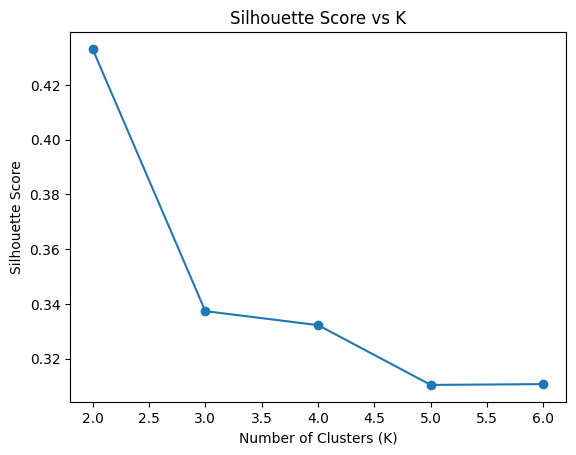

In [39]:
import matplotlib.pyplot as plt

df_scores = pd.DataFrame(results)

plt.plot(df_scores["K"], df_scores["Silhouette Score"], marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs K")
plt.show()

# 10. Train Final K-Means

#### Train final model

In [40]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(scaled_features)

rfm.head()

,CustomerID,Recency,Frequency,Monetary,Recency_log,Frequency_log,Monetary_log,Cluster
0,12346.0,326,1,42.075,5.789960,0.693147,3.762943,2
1,12347.0,2,7,3763.670,1.098612,2.079442,8.233415,3
2,12348.0,75,4,1106.540,4.330733,1.609438,7.009897,0
3,12349.0,19,1,1439.875,2.995732,0.693147,7.273006,1
4,12350.0,310,1,334.400,5.739793,0.693147,5.815324,2


#### Cluster counts

In [41]:
rfm["Cluster"].value_counts()

Cluster
2    1557
0    1211
1     863
3     707
Name: count, dtype: int64

#### Cluster summary

In [42]:
cluster_summary = rfm.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].mean().round(2)
cluster_summary

,Recency,Frequency,Monetary
Cluster,,,
0,62.93,4.20,1384.12
1,22.36,1.89,403.05
2,191.38,1.36,297.30
3,11.25,13.73,4527.22


# 11. Business Labels

#### Assign segment names

In [43]:
# Update names after checking cluster_summary
cluster_labels = {
    0: "High Value Customers",
    1: "Inactive Customers",
    2: "Regular Customers",
    3: "Low Spend Customers"
}

rfm["SegmentName"] = rfm["Cluster"].map(cluster_labels)

rfm[["CustomerID", "Cluster", "SegmentName"]].head()

,CustomerID,Cluster,SegmentName
0,12346.0,2,Regular Customers
1,12347.0,3,Low Spend Customers
2,12348.0,0,High Value Customers
3,12349.0,1,Inactive Customers
4,12350.0,2,Regular Customers


#### Segment counts

In [44]:
segment_counts = rfm["SegmentName"].value_counts()
segment_counts

SegmentName
Regular Customers       1557
High Value Customers    1211
Inactive Customers       863
Low Spend Customers      707
Name: count, dtype: int64

#### Plot segment counts

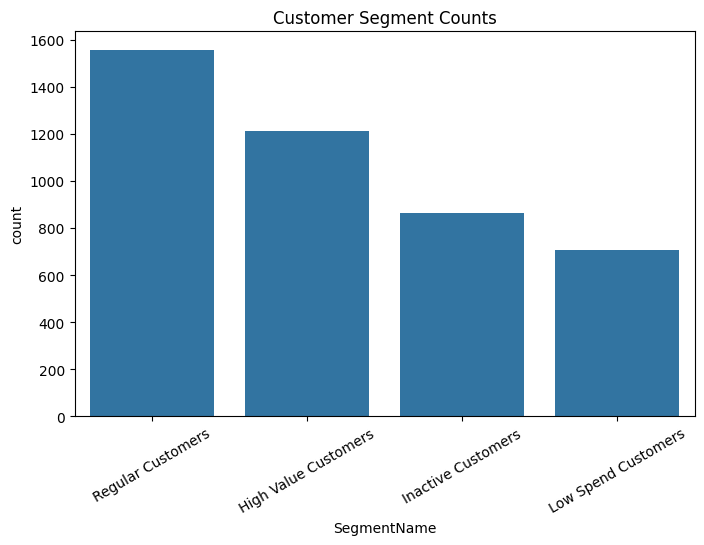

In [45]:
plt.figure(figsize=(8,5))
sns.countplot(x="SegmentName", data=rfm, order=rfm["SegmentName"].value_counts().index)
plt.title("Customer Segment Counts")
plt.xticks(rotation=30)
plt.show()

# 12. Visualization with PCA

#### PCA for 2D visualization

In [46]:
pca = PCA(n_components=2)
pca_features = pca.fit_transform(scaled_features)

rfm["PCA1"] = pca_features[:, 0]
rfm["PCA2"] = pca_features[:, 1]

#### Plot clusters

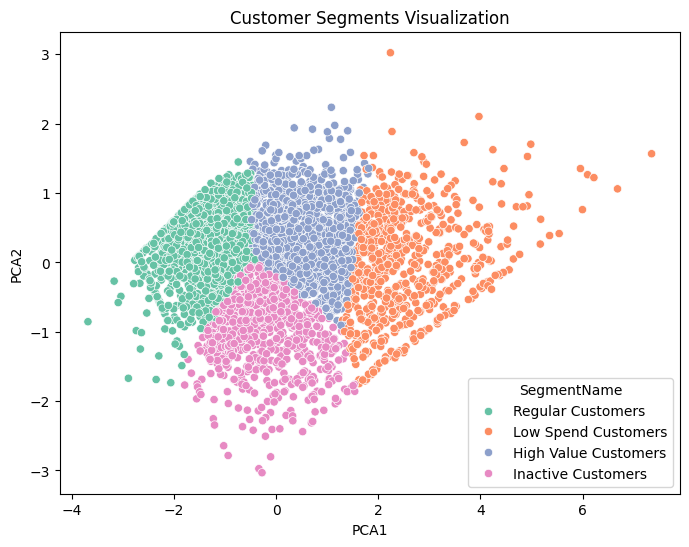

In [47]:
plt.figure(figsize=(8,6))
sns.scatterplot(x="PCA1", y="PCA2", hue="SegmentName", data=rfm, palette="Set2")
plt.title("Customer Segments Visualization")
plt.show()

#### 13. Save Segments to SQL

#### Save segmented table

In [48]:
rfm.to_sql("customer_segments", conn, if_exists="replace", index=False)
print("Segmented customer table saved successfully")

Segmented customer table saved successfully


#### SQL on segments

In [49]:
query7 = """
SELECT SegmentName, COUNT(*) AS total_customers
FROM customer_segments
GROUP BY SegmentName
ORDER BY total_customers DESC;
"""

pd.read_sql(query7, conn)

,SegmentName,total_customers
0,Regular Customers,1557
1,High Value Customers,1211
2,Inactive Customers,863
3,Low Spend Customers,707


#### Average spending by segment

In [50]:
query8 = """
SELECT SegmentName, ROUND(AVG(Monetary), 2) AS avg_spending
FROM customer_segments
GROUP BY SegmentName
ORDER BY avg_spending DESC;
"""

pd.read_sql(query8, conn)

,SegmentName,avg_spending
0,Low Spend Customers,4527.22
1,High Value Customers,1384.12
2,Inactive Customers,403.05
3,Regular Customers,297.30


#### Average recency by segment

In [51]:
query9 = """
SELECT SegmentName, ROUND(AVG(Recency), 2) AS avg_recency
FROM customer_segments
GROUP BY SegmentName
ORDER BY avg_recency ASC;
"""

pd.read_sql(query9, conn)

,SegmentName,avg_recency
0,Low Spend Customers,11.25
1,Inactive Customers,22.36
2,High Value Customers,62.93
3,Regular Customers,191.38


#### Close connection

In [52]:
conn.close()

# Final Summary 

In [53]:
# Save cleaned data
df.to_csv("customer_data_cleaned.csv", index=False)

# Save segmented output
rfm.to_csv("customer_segments.csv", index=False)


#### Deployment

This project was deployed using Streamlit to create an interactive dashboard.

Features:
- Upload dataset
- Perform SQL analysis
- Generate RFM features
- Run K-Means clustering
- Visualize customer segments
- Download results

#### Conclusion

In [54]:
print("Project Completed Successfully")
print("Built advanced customer segmentation using SQL, RFM analysis, and K-Means clustering.")
print("Generated business-friendly customer groups for marketing and retention strategy.")

Project Completed Successfully
Built advanced customer segmentation using SQL, RFM analysis, and K-Means clustering.
Generated business-friendly customer groups for marketing and retention strategy.
